In [66]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Display settings
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [67]:
df = pd.read_csv(r"C:\Users\Ankita\OneDrive\Documents\NetTech_Employee_Performance_Dataset.csv")

print("Dataset loaded successfully.")

Dataset loaded successfully.


In [68]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of records: 51
Number of columns: 10


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee Name       51 non-null     object 
 1   Department          51 non-null     object 
 2   Attendance (%)      51 non-null     int64  
 3   Projects Completed  51 non-null     int64  
 4   Performance Score   51 non-null     int64  
 5   Salary              51 non-null     int64  
 6   Experience (Years)  51 non-null     float64
 7   Training Hours      50 non-null     float64
 8   Overtime Hours      51 non-null     int64  
 9   Satisfaction Score  51 non-null     float64
dtypes: float64(3), int64(5), object(2)
memory usage: 4.1+ KB


## Data Cleaning
Before performing analysis, the dataset must be checked for missing values, duplicate records, inconsistent formatting, and incorrect data types.

In [70]:
df.isnull().sum()

Employee Name         0
Department            0
Attendance (%)        0
Projects Completed    0
Performance Score     0
Salary                0
Experience (Years)    0
Training Hours        1
Overtime Hours        0
Satisfaction Score    0
dtype: int64

In [71]:
print("Number of duplicate records:", df.duplicated().sum())

Number of duplicate records: 0


In [72]:
df["Department"].value_counts()

Department
Sales        12
Marketing    11
IT           11
HR           10
Finance       7
Name: count, dtype: int64

In [73]:
df[df.isnull().any(axis=1)]

,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Experience (Years),Training Hours,Overtime Hours,Satisfaction Score
41,Bhavna Shah,IT,85,7,84,59000,4.2,NaN,11,8.3


In [74]:
df["Attendance (%)"] = df["Attendance (%)"].fillna(
    df["Attendance (%)"].median()
)

df["Training Hours"] = df["Training Hours"].fillna(
    df["Training Hours"].median()
)                                                             # used to automatically fill in missing numbers

In [75]:
df = df.drop_duplicates()

In [76]:
print("Number of duplicate records:", df.duplicated().sum())
print("Number of records after cleaning:", df.shape[0])

Number of duplicate records: 0
Number of records after cleaning: 51


In [77]:
print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate records after cleaning:")
print(df.duplicated().sum())

print("\nFinal dataset shape:")
print(df.shape)                                               # final cleaning verification

Missing values after cleaning:
Employee Name         0
Department            0
Attendance (%)        0
Projects Completed    0
Performance Score     0
Salary                0
Experience (Years)    0
Training Hours        0
Overtime Hours        0
Satisfaction Score    0
dtype: int64

Duplicate records after cleaning:
0

Final dataset shape:
(51, 10)


In [78]:
df.to_csv("NetTech_Employee_Performance_Clean.csv", index=False)

print("Clean dataset saved successfully.")

Clean dataset saved successfully.


## Overall Employee Performance Analysis

In this section, we analyze the overall performance of employees
using attendance, projects completed, performance score, salary,
experience, training hours, overtime hours, and satisfaction score.

In [79]:
print("Total Employees:", df["Employee Name"].nunique())
print("Average Attendance:", round(df["Attendance (%)"].mean(), 2), "%")
print("Average Projects Completed:", round(df["Projects Completed"].mean(), 2))
print("Average Performance Score:", round(df["Performance Score"].mean(), 2))
print("Average Salary: ₹", round(df["Salary"].mean(), 2))
print("Average Experience:", round(df["Experience (Years)"].mean(), 2), "years")
print("Average Training Hours:", round(df["Training Hours"].mean(), 2))
print("Average Satisfaction Score:", round(df["Satisfaction Score"].mean(), 2))          # KPIs

Total Employees: 50
Average Attendance: 87.02 %
Average Projects Completed: 6.27
Average Performance Score: 80.14
Average Salary: ₹ 61617.65
Average Experience: 3.8 years
Average Training Hours: 23.0
Average Satisfaction Score: 7.5


In [80]:
performance_stats = df["Performance Score"].agg(
    ["mean", "median", "min", "max", "std"]
)

performance_stats                             # performance score statistics

mean       80.137255
median     82.000000
min        50.000000
max       100.000000
std        13.896790
Name: Performance Score, dtype: float64

In [81]:
attendance_stats = df["Attendance (%)"].agg(
    ["mean", "median", "min", "max", "std"]
)

attendance_stats                              # attendance analysis

mean      87.019608
median    85.000000
min       77.000000
max       99.000000
std        6.528369
Name: Attendance (%), dtype: float64

In [82]:
project_stats = df["Projects Completed"].agg(
    ["mean", "median", "min", "max", "std"]
)

project_stats                                 # projects completed analysis

mean       6.274510
median     6.000000
min        3.000000
max       11.000000
std        1.744459
Name: Projects Completed, dtype: float64

## Department-wise Statistical Analysis

This section analyzes employee performance across different departments.
The analysis includes employee count, average attendance, projects completed,
performance score, salary, and other numerical measures.

In [83]:
department_count = df["Department"].value_counts()

department_count

Department
Sales        12
Marketing    11
IT           11
HR           10
Finance       7
Name: count, dtype: int64

In [84]:
department_avg = df.groupby("Department").agg({
    "Attendance (%)": "mean",
    "Projects Completed": "mean",
    "Performance Score": "mean",
    "Salary": "mean",
    "Experience (Years)": "mean",
    "Training Hours": "mean",
    "Overtime Hours": "mean",
    "Satisfaction Score": "mean"
}).round(2)

department_avg                                  # department-wise statistics

,Attendance (%),Projects Completed,Performance Score,Salary,Experience (Years),Training Hours,Overtime Hours,Satisfaction Score
Department,,,,,,,,
Finance,86.00,6.71,75.00,59142.86,3.20,25.29,10.43,7.91
HR,86.40,5.90,81.90,61750.00,3.74,24.90,9.50,7.26
IT,86.91,6.00,86.55,62000.00,3.89,20.45,12.91,7.65
Marketing,86.73,5.91,79.73,57409.09,2.82,23.27,9.64,7.06
Sales,88.50,6.92,76.17,66458.33,5.03,22.17,9.83,7.74


In [85]:
department_stats = df.groupby("Department").agg({
    "Attendance (%)": ["mean", "median", "min", "max", "std"],
    "Projects Completed": ["mean", "median", "min", "max", "std"],
    "Performance Score": ["mean", "median", "min", "max", "std"],
    "Salary": ["mean", "median", "min", "max", "std"]
}).round(2)

department_stats                                  # detailed statistical summary

Attendance (%)                      Projects Completed             \
                     mean median min max   std               mean median min   
Department                                                                     
Finance             86.00   89.0  78  91  5.54               6.71    6.0   5   
HR                  86.40   84.5  78  97  7.38               5.90    5.0   3   
IT                  86.91   86.0  77  99  6.27               6.00    6.0   3   
Marketing           86.73   86.0  77  96  6.94               5.91    6.0   4   
Sales               88.50   85.0  78  99  7.03               6.92    7.0   5   

                     Performance Score                           Salary  \
           max   std              mean median min  max    std      mean   
Department                                                                
Finance      9  1.60             75.00   76.0  51   96  17.08  59142.86   
HR          11  2.38             81.90   78.0  66   96  10.89  61750.00   
IT          10  1.84             86.55   88.0  68   99   9.05  62000.00   
Marketing    8  1.45             79.73   82.0  50  100  15.99  57409.09   
Sales        9  1.38             76.17   82.0  55   96  15.38  66458.33   

                                             
             median    min    max       std  
Department                                   
Finance     59000.0  43500  79000  10726.58  
HR          63250.0  50000  73000   8087.20  
IT          64000.0  50000  74000   8276.47  
Marketing   56500.0  47000  68000   6995.78  
Sales       67250.0  53500  78000   7027.41

In [86]:
department_summary = df.groupby("Department").agg(
    Employee_Count=("Employee Name", "count"),
    Average_Attendance=("Attendance (%)", "mean"),
    Average_Projects=("Projects Completed", "mean"),
    Average_Performance=("Performance Score", "mean"),
    Average_Salary=("Salary", "mean"),
    Average_Experience=("Experience (Years)", "mean"),
    Average_Training=("Training Hours", "mean"),
    Average_Overtime=("Overtime Hours", "mean"),
    Average_Satisfaction=("Satisfaction Score", "mean")
).round(2)

department_summary                                   # avg for key performance factors

,Employee_Count,Average_Attendance,Average_Projects,Average_Performance,Average_Salary,Average_Experience,Average_Training,Average_Overtime,Average_Satisfaction
Department,,,,,,,,,
Finance,7,86.00,6.71,75.00,59142.86,3.20,25.29,10.43,7.91
HR,10,86.40,5.90,81.90,61750.00,3.74,24.90,9.50,7.26
IT,11,86.91,6.00,86.55,62000.00,3.89,20.45,12.91,7.65
Marketing,11,86.73,5.91,79.73,57409.09,2.82,23.27,9.64,7.06
Sales,12,88.50,6.92,76.17,66458.33,5.03,22.17,9.83,7.74


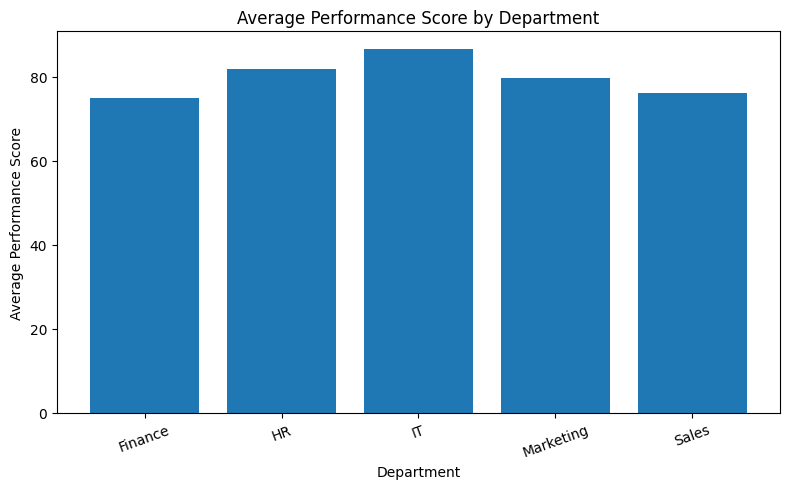

In [87]:
plt.figure(figsize=(8, 5))

plt.bar(
    department_summary.index,
    department_summary["Average_Performance"]
)

plt.title("Average Performance Score by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Score")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

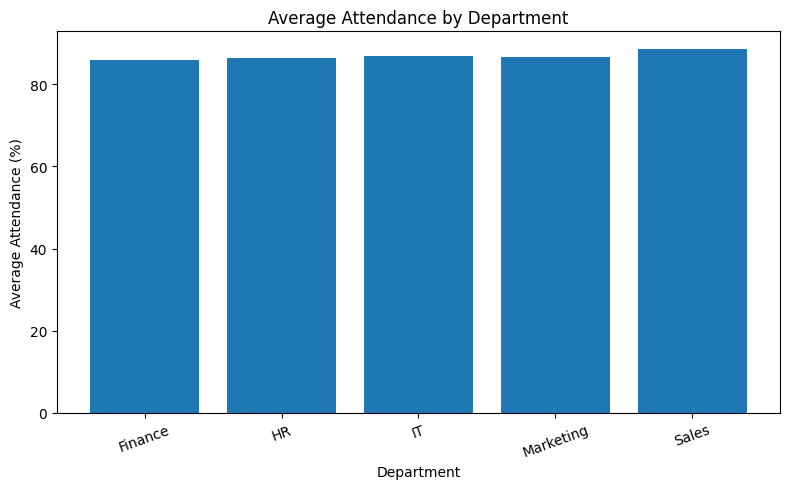

In [88]:
plt.figure(figsize=(8, 5))

plt.bar(
    department_summary.index,
    department_summary["Average_Attendance"]
)

plt.title("Average Attendance by Department")
plt.xlabel("Department")
plt.ylabel("Average Attendance (%)")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

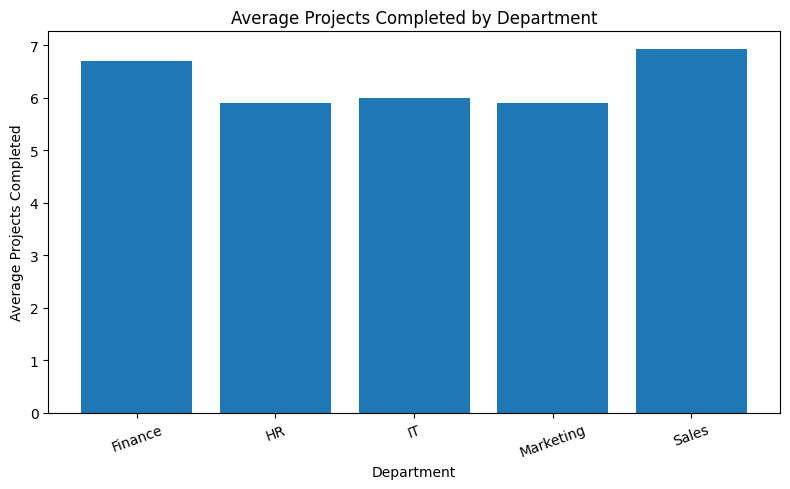

In [89]:
plt.figure(figsize=(8, 5))

plt.bar(
    department_summary.index,
    department_summary["Average_Projects"]
)

plt.title("Average Projects Completed by Department")
plt.xlabel("Department")
plt.ylabel("Average Projects Completed")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

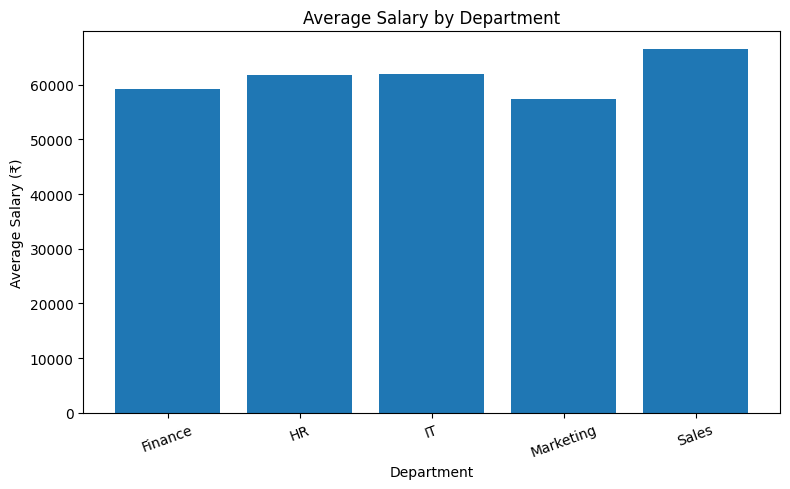

In [90]:
plt.figure(figsize=(8, 5))

plt.bar(
    department_summary.index,
    department_summary["Average_Salary"]
)

plt.title("Average Salary by Department")
plt.xlabel("Department")
plt.ylabel("Average Salary (₹)")

plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

## Correlation & Relationship Analysis

In [91]:
correlation_columns = [
    "Attendance (%)",
    "Projects Completed",
    "Performance Score",
    "Salary",
    "Experience (Years)",
    "Training Hours",
    "Overtime Hours",
    "Satisfaction Score"
]

correlation_df = df[correlation_columns]

correlation_df.head()                                             # numerical variables

,Attendance (%),Projects Completed,Performance Score,Salary,Experience (Years),Training Hours,Overtime Hours,Satisfaction Score
0,79,7,86,62500,3.3,24.0,7,6.7
1,78,9,55,78000,7.6,32.0,15,7.5
2,86,6,91,74000,6.0,9.0,11,8.2
3,93,7,99,68000,5.0,23.0,3,8.6
4,84,7,82,60000,1.7,24.0,11,6.3


In [92]:
correlation_matrix = correlation_df.corr().round(2)

correlation_matrix

,Attendance (%),Projects Completed,Performance Score,Salary,Experience (Years),Training Hours,Overtime Hours,Satisfaction Score
Attendance (%),1.00,0.00,0.06,0.25,0.33,0.06,-0.15,0.04
Projects Completed,0.00,1.00,0.04,0.33,0.30,-0.00,0.08,0.03
Performance Score,0.06,0.04,1.00,0.03,-0.24,-0.07,-0.21,-0.27
Salary,0.25,0.33,0.03,1.00,0.83,0.03,-0.08,-0.01
Experience (Years),0.33,0.30,-0.24,0.83,1.00,0.03,0.04,0.05
Training Hours,0.06,-0.00,-0.07,0.03,0.03,1.00,0.03,-0.14
Overtime Hours,-0.15,0.08,-0.21,-0.08,0.04,0.03,1.00,0.29
Satisfaction Score,0.04,0.03,-0.27,-0.01,0.05,-0.14,0.29,1.00


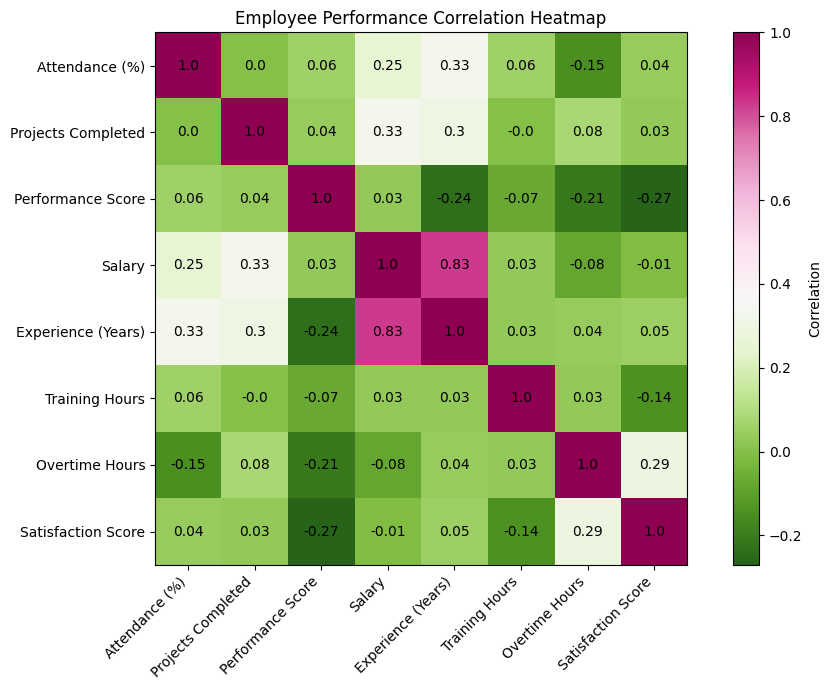

In [93]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation_matrix, cmap="PiYG_r", interpolation="nearest")

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Employee Performance Correlation Heatmap")

for i in range(len(correlation_matrix.columns)):
    for j in range(len(correlation_matrix.columns)):
        plt.text(
            j,
            i,
            correlation_matrix.iloc[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [94]:
performance_correlation = (
    correlation_matrix["Performance Score"]
    .sort_values(ascending=False)
)

performance_correlation

Performance Score     1.00
Attendance (%)        0.06
Projects Completed    0.04
Salary                0.03
Training Hours       -0.07
Overtime Hours       -0.21
Experience (Years)   -0.24
Satisfaction Score   -0.27
Name: Performance Score, dtype: float64

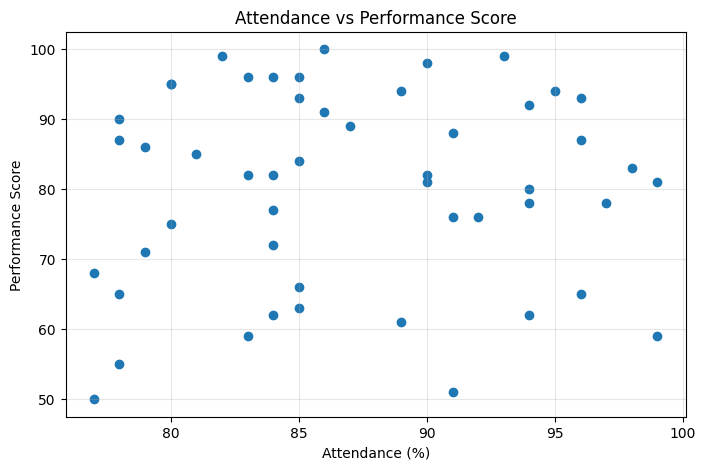

In [95]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Attendance (%)"],
    df["Performance Score"]
)

plt.title("Attendance vs Performance Score")
plt.xlabel("Attendance (%)")
plt.ylabel("Performance Score")

plt.grid(alpha=0.3)
plt.show()

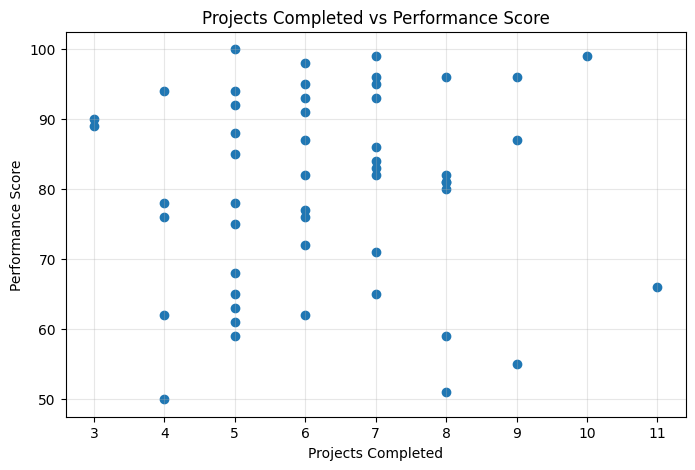

In [96]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Projects Completed"],
    df["Performance Score"]
)

plt.title("Projects Completed vs Performance Score")
plt.xlabel("Projects Completed")
plt.ylabel("Performance Score")

plt.grid(alpha=0.3)
plt.show()

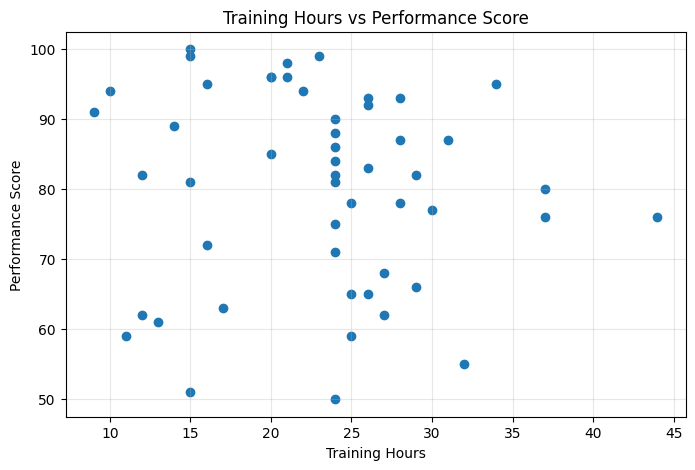

In [97]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Training Hours"],
    df["Performance Score"]
)

plt.title("Training Hours vs Performance Score")
plt.xlabel("Training Hours")
plt.ylabel("Performance Score")

plt.grid(alpha=0.3)
plt.show()

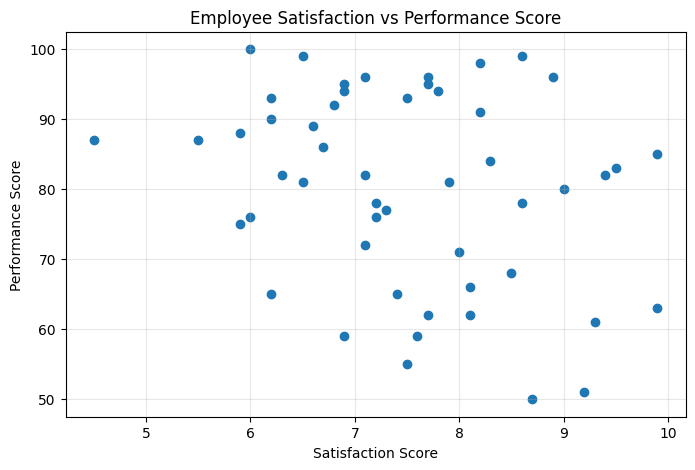

In [98]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df["Satisfaction Score"],
    df["Performance Score"]
)

plt.title("Employee Satisfaction vs Performance Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Performance Score")

plt.grid(alpha=0.3)
plt.show()

# Top Performers & Performance Segmentation

In [99]:
top_performers = df.sort_values(
    by="Performance Score",
    ascending=False
).head(10)

top_performers[
    [
        "Employee Name",
        "Department",
        "Performance Score",
        "Attendance (%)",
        "Projects Completed",
        "Satisfaction Score"
    ]
]

,Employee Name,Department,Performance Score,Attendance (%),Projects Completed,Satisfaction Score
31,Mitali Shah,Marketing,100,86,5,6.0
23,Aditi Joshi,IT,99,82,10,6.5
3,Priya Deshmukh,Marketing,99,93,7,8.6
47,Mansi Desai,IT,98,90,6,8.2
28,Varun Reddy,HR,96,84,8,7.1
32,Raj Malhotra,Finance,96,83,9,8.9
38,Tejas Joshi,Sales,96,85,7,7.7
37,Payal Mehta,Finance,95,80,6,6.9
29,Sakshi Jadhav,HR,95,80,7,7.7
49,Isha Menon,Marketing,94,89,4,6.9


In [100]:
df["Performance Rank"] = (
    df["Performance Score"]
    .rank(method="dense", ascending=False)
    .astype(int)
)

employee_ranking = df.sort_values(
    by="Performance Rank"
)

employee_ranking[
    [
        "Performance Rank",
        "Employee Name",
        "Department",
        "Performance Score"
    ]
].head(15)

,Performance Rank,Employee Name,Department,Performance Score
31,1,Mitali Shah,Marketing,100
3,2,Priya Deshmukh,Marketing,99
23,2,Aditi Joshi,IT,99
47,3,Mansi Desai,IT,98
32,4,Raj Malhotra,Finance,96
38,4,Tejas Joshi,Sales,96
28,4,Varun Reddy,HR,96
29,5,Sakshi Jadhav,HR,95
37,5,Payal Mehta,Finance,95
36,6,Aniket Deshmukh,HR,94


In [101]:
def performance_category(score):
    if score >= 90:
        return "Excellent"
    elif score >= 80:
        return "Good"
    elif score >= 70:
        return "Average"
    else:
        return "Needs Improvement"

df["Performance Category"] = df["Performance Score"].apply(
    performance_category
)

In [102]:
df["Performance Category"].value_counts()

Performance Category
Excellent            16
Good                 14
Needs Improvement    13
Average               8
Name: count, dtype: int64

In [103]:
performance_summary = (
    df.groupby("Performance Category")
    .agg(
        Employee_Count=("Employee Name", "count"),
        Average_Performance=("Performance Score", "mean"),
        Average_Attendance=("Attendance (%)", "mean"),
        Average_Projects=("Projects Completed", "mean"),
        Average_Satisfaction=("Satisfaction Score", "mean")
    )
    .round(2)
)

performance_summary

,Employee_Count,Average_Performance,Average_Attendance,Average_Projects,Average_Satisfaction
Performance Category,,,,,
Average,8,75.38,87.62,5.38,7.16
Excellent,16,95.06,86.62,6.31,7.32
Good,14,84.07,88.21,6.71,7.36
Needs Improvement,13,60.46,85.85,6.31,8.08


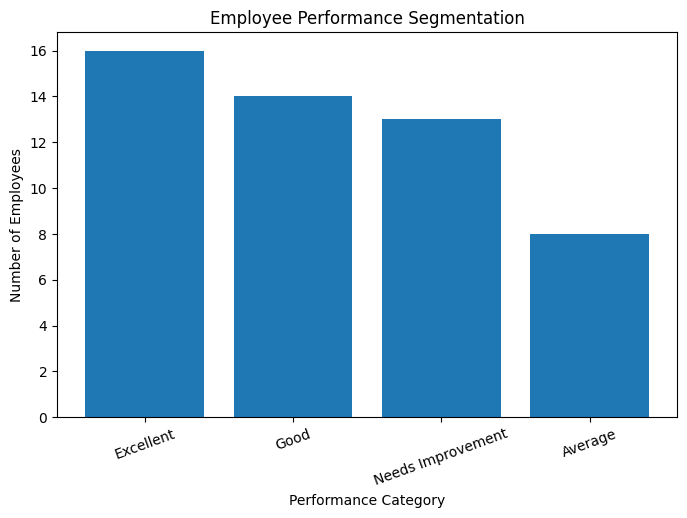

In [104]:
category_counts = df["Performance Category"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title("Employee Performance Segmentation")
plt.xlabel("Performance Category")
plt.ylabel("Number of Employees")
plt.xticks(rotation=20)

plt.show()

In [105]:
top_department_performers = (
    df.sort_values("Performance Score", ascending=False)
    .groupby("Department")
    .head(3)
)

top_department_performers[
    [
        "Employee Name",
        "Department",
        "Performance Score",
        "Attendance (%)",
        "Projects Completed"
    ]
].sort_values(
    ["Department", "Performance Score"],
    ascending=[True, False]
)                                                     # top 3 performers from each department

,Employee Name,Department,Performance Score,Attendance (%),Projects Completed
32,Raj Malhotra,Finance,96,83,9
37,Payal Mehta,Finance,95,80,6
34,Saurabh Kulkarni,Finance,81,90,8
28,Varun Reddy,HR,96,84,8
29,Sakshi Jadhav,HR,95,80,7
36,Aniket Deshmukh,HR,94,95,5
23,Aditi Joshi,IT,99,82,10
47,Mansi Desai,IT,98,90,6
17,Tanvi Desai,IT,92,94,5
31,Mitali Shah,Marketing,100,86,5


In [106]:
category_performance = (
    df.groupby("Performance Category")["Performance Score"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

category_performance

Performance Category
Excellent            95.06
Good                 84.07
Average              75.38
Needs Improvement    60.46
Name: Performance Score, dtype: float64

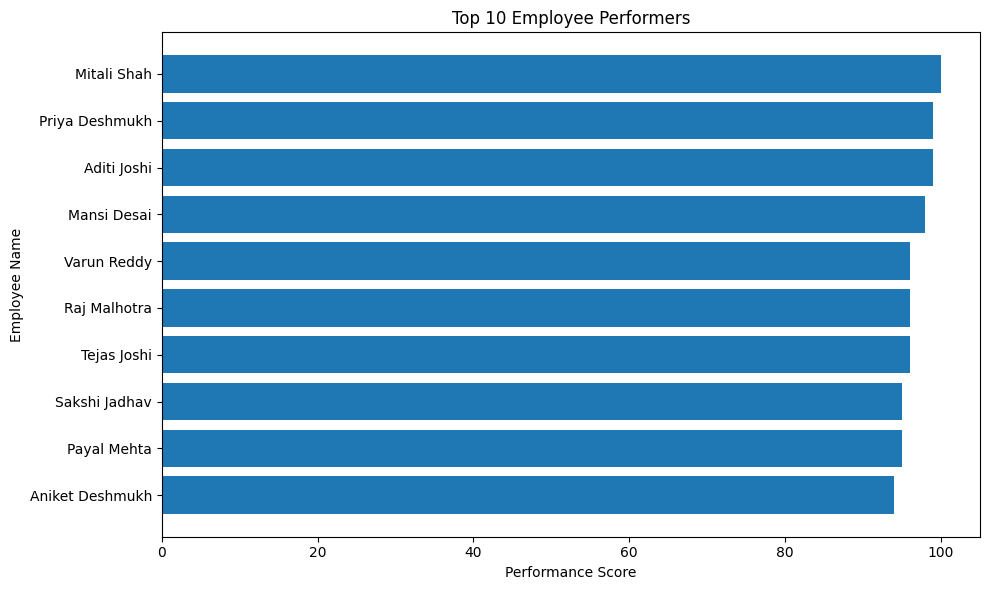

In [107]:
top_10 = df.nlargest(10, "Performance Score")

plt.figure(figsize=(10, 6))

plt.barh(
    top_10["Employee Name"],
    top_10["Performance Score"]
)

plt.title("Top 10 Employee Performers")
plt.xlabel("Performance Score")
plt.ylabel("Employee Name")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## Individual Employee Performance Analysis

In [108]:
employee_name = input("Enter Employee Name: ")

employee = df[
    df["Employee Name"].str.lower() == employee_name.strip().lower()
]

if employee.empty:
    print("Employee not found. Please check the employee name.")
else:
    employee_details = employee[
        [
            "Employee Name",
            "Department",
            "Attendance (%)",
            "Projects Completed",
            "Performance Score",
            "Salary",
            "Experience (Years)",
            "Training Hours",
            "Overtime Hours",
            "Satisfaction Score"
        ]
    ]

    display(employee_details)                           # to get the data of individual employee need to run the cell and type the name of an employee

Enter Employee Name:  Sakshi Jadhav


,Employee Name,Department,Attendance (%),Projects Completed,Performance Score,Salary,Experience (Years),Training Hours,Overtime Hours,Satisfaction Score
29,Sakshi Jadhav,HR,80,7,95,52500,0.8,16.0,10,7.7


In [109]:
if not employee.empty:

    department = employee.iloc[0]["Department"]

    department_avg = df[
        df["Department"] == department
    ]["Performance Score"].mean()

    employee_score = employee.iloc[0]["Performance Score"]

    print("\nINDIVIDUAL EMPLOYEE ANALYSIS")
    print("-" * 45)

    print(f"Employee Name       : {employee.iloc[0]['Employee Name']}")
    print(f"Department          : {department}")
    print(f"Performance Score   : {employee_score}")
    print(f"Department Average  : {department_avg:.2f}")

    if employee_score > department_avg:
        print("Performance Status  : Above Department Average")
    elif employee_score < department_avg:
        print("Performance Status  : Below Department Average")
    else:
        print("Performance Status  : Equal to Department Average")


INDIVIDUAL EMPLOYEE ANALYSIS
---------------------------------------------
Employee Name       : Sakshi Jadhav
Department          : HR
Performance Score   : 95
Department Average  : 81.90
Performance Status  : Above Department Average


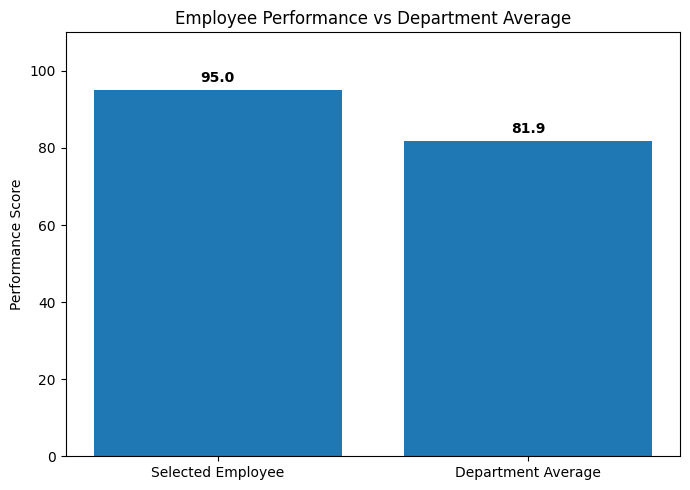

In [110]:
import matplotlib.pyplot as plt

if not employee.empty:

    employee_score = employee.iloc[0]["Performance Score"]

    plt.figure(figsize=(7, 5))

    plt.bar(
        ["Selected Employee", "Department Average"],
        [employee_score, department_avg]
    )

    plt.title("Employee Performance vs Department Average")
    plt.ylabel("Performance Score")
    plt.ylim(0, 110)

    # Add values on top of bars
    plt.text(0, employee_score + 2, f"{employee_score:.1f}",
             ha="center", fontweight="bold")

    plt.text(1, department_avg + 2, f"{department_avg:.1f}",
             ha="center", fontweight="bold")

    plt.tight_layout()
    plt.show()

# Interactive Visualizations & Dashboard

In [111]:
dashboard_kpis = {
    "Total Employees": df["Employee Name"].nunique(),
    "Average Attendance": round(df["Attendance (%)"].mean(), 2),
    "Average Performance": round(df["Performance Score"].mean(), 2),
    "Average Projects": round(df["Projects Completed"].mean(), 2),
    "Average Salary": round(df["Salary"].mean(), 2),
    "Average Satisfaction": round(df["Satisfaction Score"].mean(), 2)
}

dashboard_kpis                                                  # key performance indicators

{'Total Employees': 50,
 'Average Attendance': np.float64(87.02),
 'Average Performance': np.float64(80.14),
 'Average Projects': np.float64(6.27),
 'Average Salary': np.float64(61617.65),
 'Average Satisfaction': np.float64(7.5)}

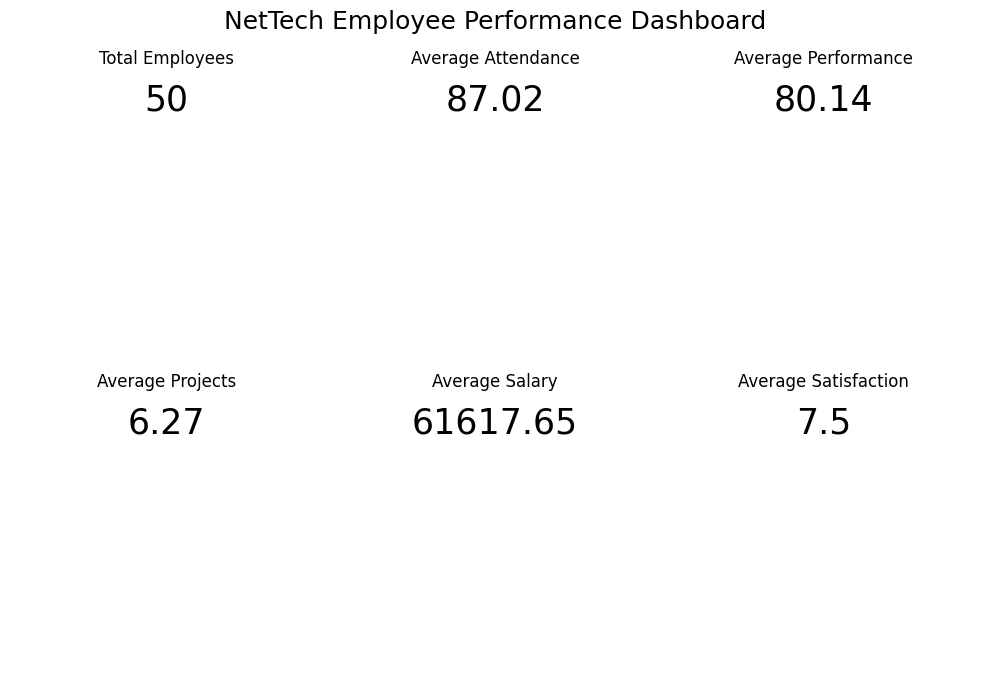

In [112]:
fig, axes = plt.subplots(2, 3, figsize=(10, 7))

kpi_values = [
    df["Employee Name"].nunique(),
    round(df["Attendance (%)"].mean(), 2),
    round(df["Performance Score"].mean(), 2),
    round(df["Projects Completed"].mean(), 2),
    round(df["Salary"].mean(), 2),
    round(df["Satisfaction Score"].mean(), 2)
]

kpi_titles = [
    "Total Employees",
    "Average Attendance",
    "Average Performance",
    "Average Projects",
    "Average Salary",
    "Average Satisfaction"
]

for ax, title, value in zip(axes.flatten(), kpi_titles, kpi_values):
    ax.text(
        0.5, 0.9,
        str(value),
        fontsize=25,
        ha="center",
        va="center"
    )
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    "NetTech Employee Performance Dashboard",
    fontsize=18,
)

plt.tight_layout()
plt.show()

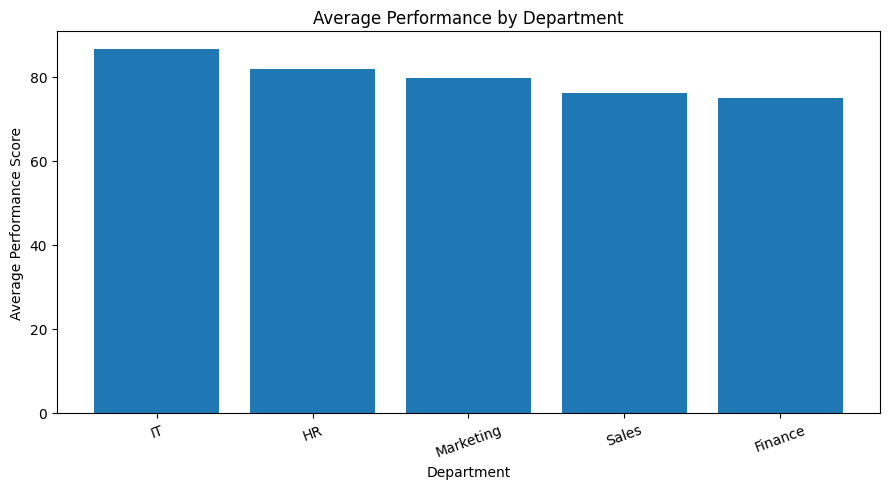

In [113]:
department_performance = (
    df.groupby("Department")["Performance Score"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    department_performance.index,
    department_performance.values
)

plt.title("Average Performance by Department")
plt.xlabel("Department")
plt.ylabel("Average Performance Score")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

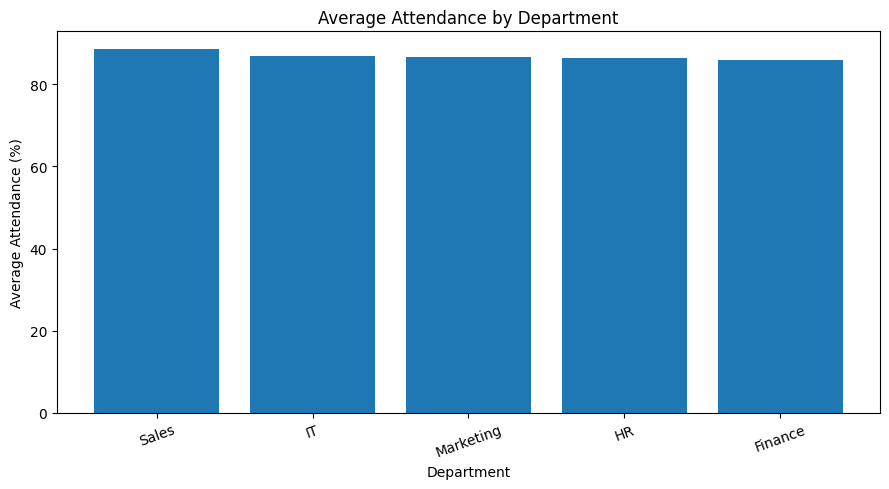

In [114]:
department_attendance = (
    df.groupby("Department")["Attendance (%)"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    department_attendance.index,
    department_attendance.values
)

plt.title("Average Attendance by Department")
plt.xlabel("Department")
plt.ylabel("Average Attendance (%)")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

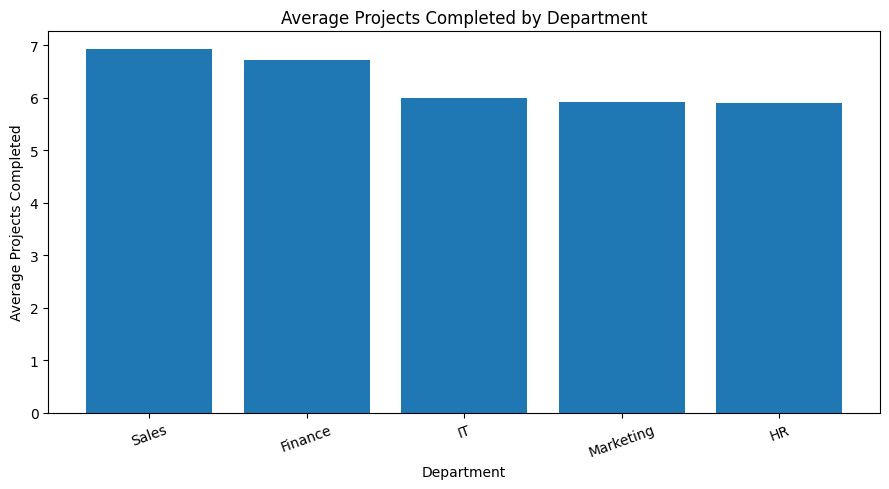

In [115]:
department_projects = (
    df.groupby("Department")["Projects Completed"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    department_projects.index,
    department_projects.values
)

plt.title("Average Projects Completed by Department")
plt.xlabel("Department")
plt.ylabel("Average Projects Completed")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

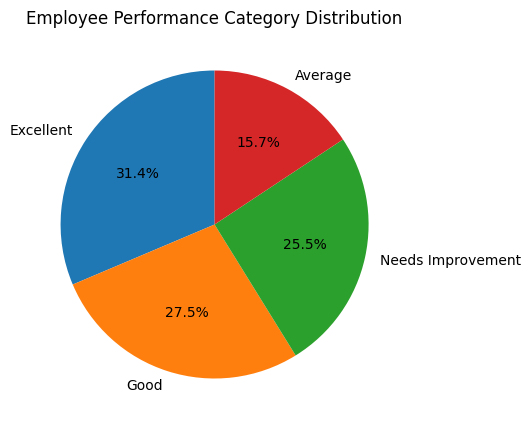

In [116]:
category_counts = df["Performance Category"].value_counts()

plt.figure(figsize=(8, 5))

plt.pie(
    category_counts.values,
    labels=category_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Employee Performance Category Distribution")

plt.show()

In [117]:
import ipywidgets as widgets
from IPython.display import display, clear_output

In [118]:
department_filter = widgets.Dropdown(
    options=["All Departments"] + sorted(df["Department"].unique().tolist()),
    description="Department:"
)

output = widgets.Output()

def update_dashboard(change):
    with output:
        clear_output(wait=True)

        selected_department = change["new"]

        if selected_department == "All Departments":
            filtered_df = df.copy()
        else:
            filtered_df = df[
                df["Department"] == selected_department
            ]

        print("Department:", selected_department)
        print("Employees:", filtered_df["Employee Name"].nunique())
        print(
            "Average Performance:",
            round(filtered_df["Performance Score"].mean(), 2)
        )
        print(
            "Average Attendance:",
            round(filtered_df["Attendance (%)"].mean(), 2)
        )
        print(
            "Average Projects:",
            round(filtered_df["Projects Completed"].mean(), 2)
        )

department_filter.observe(update_dashboard, names="value")

display(department_filter, output)

update_dashboard({"new": "All Departments"})

Dropdown(description='Department:', options=('All Departments', 'Finance', 'HR', 'IT', 'Marketing', 'Sales'), …

Output()

# Summary Report & Final Insights

In [119]:
overall_summary = {
    "Total Employees": df["Employee Name"].nunique(),
    "Average Attendance (%)": round(df["Attendance (%)"].mean(), 2),
    "Average Projects Completed": round(df["Projects Completed"].mean(), 2),
    "Average Performance Score": round(df["Performance Score"].mean(), 2),
    "Average Salary": round(df["Salary"].mean(), 2),
    "Average Experience (Years)": round(df["Experience (Years)"].mean(), 2),
    "Average Training Hours": round(df["Training Hours"].mean(), 2),
    "Average Overtime Hours": round(df["Overtime Hours"].mean(), 2),
    "Average Satisfaction Score": round(df["Satisfaction Score"].mean(), 2)
}

overall_summary

{'Total Employees': 50,
 'Average Attendance (%)': np.float64(87.02),
 'Average Projects Completed': np.float64(6.27),
 'Average Performance Score': np.float64(80.14),
 'Average Salary': np.float64(61617.65),
 'Average Experience (Years)': np.float64(3.8),
 'Average Training Hours': np.float64(23.0),
 'Average Overtime Hours': np.float64(10.47),
 'Average Satisfaction Score': np.float64(7.5)}

In [120]:
highest_performing_department = (
    department_summary["Average_Performance"]
    .idxmax()
)

highest_performance_score = (
    department_summary["Average_Performance"]
    .max()
)

print("Highest Average Performing Department:", highest_performing_department)
print("Average Performance Score:", highest_performance_score)

Highest Average Performing Department: IT
Average Performance Score: 86.55


In [121]:
highest_attendance_department = (
    department_summary["Average_Attendance"]
    .idxmax()
)

highest_attendance = (
    department_summary["Average_Attendance"]
    .max()
)

print("Department with Highest Average Attendance:",
      highest_attendance_department)

print("Average Attendance:",
      highest_attendance, "%")

Department with Highest Average Attendance: Sales
Average Attendance: 88.5 %


In [122]:
top_employee = df.loc[
    df["Performance Score"].idxmax()
]

print("Top Performer:", top_employee["Employee Name"])
print("Department:", top_employee["Department"])
print("Performance Score:", top_employee["Performance Score"])
print("Attendance:", top_employee["Attendance (%)"], "%")
print("Projects Completed:", top_employee["Projects Completed"])

Top Performer: Mitali Shah
Department: Marketing
Performance Score: 100
Attendance: 86 %
Projects Completed: 5


In [123]:
print("KEY INSIGHTS")
print("-" * 50)

print(
    f"1. The dataset contains {df['Employee Name'].nunique()} employees "
    f"across {df['Department'].nunique()} departments."
)

print(
    f"2. The overall average performance score is "
    f"{df['Performance Score'].mean():.2f}."
)

print(
    f"3. The average employee attendance is "
    f"{df['Attendance (%)'].mean():.2f}%."
)

print(
    f"4. Employees complete an average of "
    f"{df['Projects Completed'].mean():.2f} projects."
)

print(
    f"5. The highest-performing department based on average "
    f"performance is {highest_performing_department}."
)

print(
    f"6. The highest individual performance score is "
    f"{df['Performance Score'].max():.2f}, achieved by "
    f"{top_employee['Employee Name']}."
)

KEY INSIGHTS
--------------------------------------------------
1. The dataset contains 50 employees across 5 departments.
2. The overall average performance score is 80.14.
3. The average employee attendance is 87.02%.
4. Employees complete an average of 6.27 projects.
5. The highest-performing department based on average performance is IT.
6. The highest individual performance score is 100.00, achieved by Mitali Shah.


In [124]:
final_summary = pd.DataFrame({
    "Metric": [
        "Total Employees",
        "Total Departments",
        "Average Attendance (%)",
        "Average Projects Completed",
        "Average Performance Score",
        "Average Salary",
        "Average Experience (Years)",
        "Average Training Hours",
        "Average Overtime Hours",
        "Average Satisfaction Score",
        "Top Performer",
        "Highest Performing Department"
    ],
    
    "Value": [
        df["Employee Name"].nunique(),
        df["Department"].nunique(),
        round(df["Attendance (%)"].mean(), 2),
        round(df["Projects Completed"].mean(), 2),
        round(df["Performance Score"].mean(), 2),
        round(df["Salary"].mean(), 2),
        round(df["Experience (Years)"].mean(), 2),
        round(df["Training Hours"].mean(), 2),
        round(df["Overtime Hours"].mean(), 2),
        round(df["Satisfaction Score"].mean(), 2),
        top_employee["Employee Name"],
        highest_performing_department
    ]
})

final_summary                                            # key project metrics

,Metric,Value
0,Total Employees,50
1,Total Departments,5
2,Average Attendance (%),87.02
3,Average Projects Completed,6.27
4,Average Performance Score,80.14
5,Average Salary,61617.65
6,Average Experience (Years),3.8
7,Average Training Hours,23.0
8,Average Overtime Hours,10.47
9,Average Satisfaction Score,7.5


In [125]:
final_summary.to_csv(
    "NetTech_Employee_Performance_Summary_Report.csv",
    index=False
)

print("Summary report exported successfully.")

Summary report exported successfully.


In [126]:
department_summary.to_csv(
    "NetTech_Department_Performance_Report.csv"
)

print("Department performance report exported successfully.")

Department performance report exported successfully.


In [127]:
top_performers.to_csv(
    "NetTech_Top_Performers_Report.csv",
    index=False
)

print("Top performers report exported successfully.")

Top performers report exported successfully.


In [128]:
print("PROJECT COMPLETION CHECK")
print("-" * 50)

print("✓ Data Cleaning Completed")
print("✓ Overall Performance Analysis Completed")
print("✓ Department-wise Statistical Analysis Completed")
print("✓ Correlation Analysis Completed")
print("✓ Top Performer Analysis Completed")
print("✓ Dashboard Visualizations Completed")
print("✓ Summary Reports Exported")

print("\nNetTech Employee Performance Dashboard Project Completed Successfully!")

PROJECT COMPLETION CHECK
--------------------------------------------------
✓ Data Cleaning Completed
✓ Overall Performance Analysis Completed
✓ Department-wise Statistical Analysis Completed
✓ Correlation Analysis Completed
✓ Top Performer Analysis Completed
✓ Dashboard Visualizations Completed
✓ Summary Reports Exported

NetTech Employee Performance Dashboard Project Completed Successfully!
